# 12. Interpretabilidad por componente: canales y horas

Este notebook desarrolla únicamente el **apartado 3.3**: usamos **Integrated Gradients (IG)** para responder qué canales y qué horas de la ventana influyen en las alertas de desarrollo de cada componente del Transformer. Después contrastamos sus patrones con el EDA de entrenamiento.

Explicamos el modelo del paso 10, cuyos pesos permanecieron intactos en el 11. No elegimos todavía la política de mantenimiento ni examinamos prueba. Las explicaciones de esta red no se trasladan automáticamente a XGBoost u otro modelo.

## 1. Por qué Integrated Gradients y qué explicamos

IG reparte el cambio de una salida entre los valores de entrada al recorrer una línea desde una referencia hasta la ventana observada. Esto permite atribuir aportaciones a cada combinación **hora × canal**. Usamos la implementación de [Captum](https://captum.ai/api/integrated_gradients.html), basada en [Sundararajan et al., Axiomatic Attribution for Deep Networks](https://arxiv.org/abs/1703.01365).

Explicamos dos puntajes:

- **Logit binario:** valores de IG positivos apoyan una mayor señal de cualquier falla frente a la referencia.
- **Margen del componente:** `logit_comp − logit_ninguno`. Una aportación positiva apoya ese componente frente a `ninguno`; una negativa reduce ese margen. Es un contraste concreto, no todas las comparaciones posibles entre componentes.

Elegimos logits en lugar de probabilidades para evitar que la saturación de sigmoid o softmax dificulte leer el cambio de la salida. Dropout permanece apagado. Analizamos la función determinista original, no las máscaras MC ni un umbral económico final. La temperatura del paso 11 no cambia los pesos de esta red.

Modelo de máquina y antigüedad se mantienen fijos. Sus atributos condicionan la explicación, pero aquí no reciben una atribución propia; eso no significa que sean irrelevantes. IG describe el comportamiento del modelo respecto a una referencia: **no demuestra causalidad física ni ahorro por intervenir**.

## 2. Recuperar el Transformer y la preparación original

Reutilizamos `resultado_transformer` y `preparacion_10` si siguen disponibles en el mismo kernel. En una sesión nueva se recuperan las definiciones y el único ajuste del 10, con la misma configuración y selección de época. No hacemos otra búsqueda.

La preparación solo usa entrenamiento y validación. Conservamos 24 horas y 13 canales por ejemplo. Las salidas originales permiten recuperar el mismo umbral de desarrollo del 10, sin ajustar otro para conseguir explicaciones más favorables.

In [1]:
from pathlib import Path
import sys
import copy
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display
from IPython.utils.capture import capture_output
from sklearn.metrics import precision_recall_curve
from captum.attr import IntegratedGradients
from bs4 import BeautifulSoup

# Localizar el repositorio desde la raíz o desde Modelación.
actual = Path.cwd()
ruta_repo = actual if (actual / "Datos").is_dir() else actual.parent
assert (ruta_repo / "Datos").is_dir()
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta = str(ruta_repo / carpeta)
    if ruta not in sys.path:
        sys.path.insert(0, ruta)

# Recuperar la misma red del 10; no depender de haber ejecutado el 11.
if "resultado_transformer" in globals() and "preparacion_10" in globals():
    print("Se reutiliza el Transformer disponible en memoria.")
else:
    fuente_10 = nbformat.read(ruta_repo / "Modelación" / "10_transformer.ipynb", as_version=4)
    espacio_10 = {}
    with capture_output():
        for indice in [3, 6, 8]:
            exec(compile(fuente_10.cells[indice].source, "definiciones_transformer_10", "exec"), espacio_10)
    print("Sesión nueva: se reconstruye el ajuste original del notebook 10.")
    exec(compile(fuente_10.cells[15].source, "entrenamiento_transformer_10", "exec"), espacio_10)
    resultado_transformer = espacio_10["resultado_transformer"]
    preparacion_10 = espacio_10["preparacion_10"]

modelo_12 = resultado_transformer["modelo"]
modelo_12.eval()
torch.set_num_threads(1)
estado_inicial_12 = {nombre: valor.detach().clone() for nombre, valor in modelo_12.state_dict().items()}
canales_12 = list(preparacion_10["canales"])
clases_12 = ["ninguno", "comp1", "comp2", "comp3", "comp4"]
validacion_12 = preparacion_10["datasets"][24]["validación"]
entrenamiento_12 = preparacion_10["datasets"][24]["entrenamiento"]
anclas_12 = preparacion_10["anclas"][24]["validación"].reset_index(drop=True).copy()
pred_original_12 = resultado_transformer["predicciones"]
assert len(anclas_12) == 144000
assert np.array_equal(pred_original_12["y_multiclase"], anclas_12["clase_codigo"])
p_bin_12 = pred_original_12["prob_binaria"]
p_multi_12 = pred_original_12["prob_multiclase"]
precision, recall, umbrales = precision_recall_curve(pred_original_12["y_binaria"], p_bin_12)
candidatos = np.flatnonzero(precision[:-1] >= .80)
assert len(candidatos) > 0
elegido = candidatos[np.argmax(recall[:-1][candidatos])]
umbral_desarrollo_12 = float(umbrales[elegido])
anclas_12["probabilidad_binaria"] = p_bin_12
anclas_12["clase_predicha"] = p_multi_12.argmax(axis=1)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 5)
plt.rcParams["figure.dpi"] = 160
print("Época conservada:", resultado_transformer["mejor_epoca"])
print("Umbral de desarrollo recuperado:", round(umbral_desarrollo_12, 6))
print("Canales dinámicos:", len(canales_12))

Sesión nueva: se reconstruye el ajuste original del notebook 10.
Transformer | época 1 | lotes 300 / 1101
Transformer | época 1 | lotes 600 / 1101
Transformer | época 1 | lotes 900 / 1101
Transformer | FIN época 1 | PR-AUC 0.896957 | segundos 168.7
Transformer | época 2 | lotes 300 / 1101
Transformer | época 2 | lotes 600 / 1101
Transformer | época 2 | lotes 900 / 1101
Transformer | FIN época 2 | PR-AUC 0.995518 | segundos 167.1
Transformer | época 3 | lotes 300 / 1101
Transformer | época 3 | lotes 600 / 1101
Transformer | época 3 | lotes 900 / 1101
Transformer | FIN época 3 | PR-AUC 0.992549 | segundos 168.1
Transformer | época 4 | lotes 300 / 1101
Transformer | época 4 | lotes 600 / 1101
Transformer | época 4 | lotes 900 / 1101
Transformer | FIN época 4 | PR-AUC 0.992861 | segundos 167.9
Parada temprana activada.


,epoca,PR_AUC_validacion,segundos,train_total,val_total,train_binaria,val_binaria,train_multiclase,val_multiclase
0,1,0.896957,168.674816,0.205965,0.051569,0.175999,0.051994,0.250914,0.050932
1,2,0.995518,167.096121,0.043319,0.014062,0.039883,0.007921,0.048475,0.023274
2,3,0.992549,168.145789,0.015949,0.010642,0.014527,0.006612,0.018083,0.016688
3,4,0.992861,167.852376,0.012172,0.011404,0.011757,0.005622,0.012795,0.020077


Épocas ejecutadas: 4
Mejor época conservada: 2
Época conservada: 2
Umbral de desarrollo recuperado: 0.313452
Canales dinámicos: 13


## 3. Seleccionar casos sin escoger los mapas que más convengan

Consideramos una **alerta sostenida activa de desarrollo** cuando la probabilidad binaria lleva al menos tres horas consecutivas sobre el umbral original. La clase de la hora actual se obtiene por argmax de la cabeza multiclase. No contamos aquí intervenciones ni calculamos costos o anticipación: una racha activa puede abarcar varias horas y no equivale a una nueva notificación en cada una.

Tomamos casos únicamente de **octubre**, con el siguiente presupuesto fijo:

1. Por cada componente, hasta cuatro casos cuya clase predicha coincide con la etiqueta y hasta cuatro que no coinciden.
2. Para reducir ventanas casi repetidas, conservamos candidatos separados al menos 48 horas dentro de una misma máquina, componente y grupo.
3. De esos candidatos elegimos posiciones repartidas uniformemente en orden cronológico. No se eligen por su probabilidad más alta ni por cómo quede IG.

Si faltan errores de un componente, usamos los disponibles y lo mostramos; no los inventamos. Las etiquetas se consultan para describir aciertos y errores de validación, no para entrenar. Son errores respecto a la clase única del paso 04, que desempata fallas simultáneas; no son todavía falsas alarmas económicas.

Las ventanas siguen siendo una muestra descriptiva pequeña. La separación temporal reduce repetición, pero no prueba independencia entre casos.

In [2]:
def actividad_sostenida_12(tabla, probabilidades, umbral):
    """Marcar horas con una racha de al menos tres, reiniciando ante huecos."""
    activa = np.zeros(len(tabla), dtype=bool)
    for maquina, grupo in tabla.groupby("machineID", sort=True):
        racha = 0
        anterior = None
        for indice, hora in zip(grupo.index, grupo["datetime"]):
            if anterior is not None and hora - anterior != pd.Timedelta(hours=1):
                racha = 0
            racha = racha + 1 if probabilidades[indice] >= umbral else 0
            activa[indice] = racha >= 3
            anterior = hora
    return activa


def elegir_casos_12(tabla, maximo=4):
    """Separar candidatos cercanos y repartir la selección en el periodo."""
    conservados = []
    ultima_por_maquina = {}
    for fila in tabla.sort_values(["datetime", "machineID"]).itertuples():
        ultima = ultima_por_maquina.get(fila.machineID)
        if ultima is None or fila.datetime - ultima >= pd.Timedelta(hours=48):
            conservados.append(fila.Index)
            ultima_por_maquina[fila.machineID] = fila.datetime
    if len(conservados) > maximo:
        posiciones = np.linspace(0, len(conservados) - 1, maximo).astype(int)
        conservados = [conservados[posicion] for posicion in posiciones]
    return conservados


anclas_12["sostenida_activa"] = actividad_sostenida_12(anclas_12, p_bin_12, umbral_desarrollo_12)
seleccion_12 = []
resumen_seleccion_12 = []
for codigo in range(1, 5):
    componente = clases_12[codigo]
    candidatas = anclas_12.loc[(anclas_12["datetime"] >= "2015-10-01") &
                               anclas_12["sostenida_activa"] & (anclas_12["clase_predicha"] == codigo)]
    for grupo, coincide in [("Acertada", True), ("No acertada", False)]:
        tabla = candidatas.loc[(candidatas["clase_codigo"] == codigo) == coincide]
        indices = elegir_casos_12(tabla, maximo=4)
        resumen_seleccion_12.append({"componente": componente, "grupo": grupo,
                                     "horas_candidatas": len(tabla), "casos_elegidos": len(indices)})
        for indice in indices:
            fila = anclas_12.loc[indice]
            seleccion_12.append({"caso": len(seleccion_12), "indice_validacion": int(indice),
                                 "componente": componente, "codigo_componente": codigo, "grupo": grupo,
                                 "machineID": int(fila["machineID"]), "datetime": fila["datetime"],
                                 "clase_real": fila["etiqueta_multiclase"],
                                 "probabilidad_binaria": p_bin_12[indice],
                                 "probabilidad_componente": p_multi_12[indice, codigo]})
casos_12 = pd.DataFrame(seleccion_12)
resumen_seleccion_12 = pd.DataFrame(resumen_seleccion_12)
assert set(casos_12.loc[casos_12.grupo == "Acertada", "componente"]) == set(clases_12[1:])
assert (casos_12["datetime"] >= pd.Timestamp("2015-10-01")).all()
assert (casos_12["datetime"] < pd.Timestamp("2015-11-01")).all()
display(resumen_seleccion_12)
display(casos_12.drop(columns=["indice_validacion", "codigo_componente"]))

,componente,grupo,horas_candidatas,casos_elegidos
0,comp1,Acertada,178,4
1,comp1,No acertada,102,4
2,comp2,Acertada,572,4
3,comp2,No acertada,9,1
4,comp3,Acertada,170,4
5,comp3,No acertada,2,2
6,comp4,Acertada,255,4
7,comp4,No acertada,40,4


,caso,componente,grupo,machineID,datetime,clase_real,probabilidad_binaria,probabilidad_componente
0,0,comp1,Acertada,66,2015-10-01 00:00:00,comp1,0.99858,0.99962
1,1,comp1,Acertada,84,2015-10-01 08:00:00,comp1,0.99864,0.99966
2,2,comp1,Acertada,13,2015-10-22 08:00:00,comp1,0.99839,0.99954
3,3,comp1,Acertada,52,2015-10-30 08:00:00,comp1,0.99913,0.99955
4,4,comp1,No acertada,80,2015-10-01 00:00:00,ninguno,0.80642,0.97278
5,5,comp1,No acertada,21,2015-10-09 19:00:00,ninguno,0.93135,0.98427
6,6,comp1,No acertada,11,2015-10-20 20:00:00,ninguno,0.90107,0.98087
7,7,comp1,No acertada,46,2015-10-28 21:00:00,ninguno,0.99660,0.99932
8,8,comp2,Acertada,20,2015-10-01 00:00:00,comp2,0.99059,0.99532
9,9,comp2,Acertada,39,2015-10-12 08:00:00,comp2,0.99953,0.99991


### Lectura de la selección

Se explican **27 casos de octubre**: 16 con componente acertado (cuatro por componente) y 11 no acertados. Entre estos últimos hay cuatro de comp1, uno de comp2, dos de comp3 y cuatro de comp4. La tabla distingue todas las horas candidatas de los pocos ejemplos seleccionados; no son 27 fallas independientes.

La selección se hizo por orden temporal y separación entre casos, antes de calcular las atribuciones. Son horas con una alerta de desarrollo sostenida y una predicción de componente. Una hora activa no equivale a una nueva intervención. “No acertada” significa que el componente predicho no coincide con la etiqueta, sin asignar todavía un costo económico. Esta muestra pequeña permite estudiar ejemplos; no representa por sí sola todas las alertas de validación.

## 4. Referencias sanas tomadas solo de entrenamiento

Para cada máquina elegimos tres ventanas reales de entrenamiento, repartidas entre las candidatas sanas. Pedimos que las **25 etiquetas binarias desde `t − 24` hasta `t` sean cero**. Como cada una mira las siguientes 24 horas, esa unión descarta fallas registradas dentro de la ventana de entrada y en las siguientes 24 horas. No se exige ausencia de errores ni mantenimiento: sano significa aquí ausencia de fallas bajo esa regla.

Cada referencia pertenece a la misma máquina que el caso. Modelo y antigüedad se mantienen iguales a los del caso al explicar. Calculamos IG frente a cada una de las tres referencias, en lugar de inventar una ventana toda en cero o promediar primero las señales.

La referencia afecta al resultado. Por eso mostraremos también si el canal dominante cambia entre las tres opciones. La línea matemática de interpolación puede contener indicadores de error fraccionarios o combinaciones no observadas; no representa una intervención física ni una secuencia que necesariamente haya ocurrido.

In [3]:
# Marcar ventanas sanas con etiquetas de entrenamiento, sin consultar octubre ni prueba.
objetivos_train_12 = preparacion_10["objetivos"]["entrenamiento"].sort_values(["machineID", "datetime"])
marcas = []
for maquina, grupo in objetivos_train_12.groupby("machineID", sort=True):
    assert (grupo["datetime"].diff().dropna() == pd.Timedelta(hours=1)).all()
    marca = grupo[["machineID", "datetime"]].copy()
    marca["sana_amplia"] = grupo["etiqueta_binaria"].rolling(25, min_periods=25).sum().eq(0).to_numpy()
    marcas.append(marca)
marcas = pd.concat(marcas, ignore_index=True)
anclas_train_12 = preparacion_10["anclas"][24]["entrenamiento"].reset_index(drop=True).copy()
anclas_train_12["indice_dataset"] = np.arange(len(anclas_train_12))
anclas_train_12 = anclas_train_12.merge(marcas, on=["machineID", "datetime"], how="left", validate="one_to_one")
referencias_por_maquina_12 = {}
filas_referencias_12 = []
for maquina in sorted(casos_12.machineID.unique()):
    sanas = anclas_train_12.loc[(anclas_train_12.machineID == maquina) & anclas_train_12.sana_amplia].sort_values("datetime")
    assert len(sanas) >= 3
    posiciones = np.linspace(0, len(sanas) - 1, 3).astype(int)
    elegidas = sanas.iloc[posiciones]
    assert (elegidas["datetime"] + pd.Timedelta(hours=24) < pd.Timestamp("2015-09-01")).all()
    referencias_por_maquina_12[maquina] = elegidas["indice_dataset"].astype(int).tolist()
    filas_referencias_12.append({"machineID": maquina, "referencia_1": elegidas.iloc[0]["datetime"],
                                 "referencia_2": elegidas.iloc[1]["datetime"], "referencia_3": elegidas.iloc[2]["datetime"]})
tabla_referencias_12 = pd.DataFrame(filas_referencias_12)
display(tabla_referencias_12)

,machineID,referencia_1,referencia_2,referencia_3
0,3,2015-01-02 06:00:00,2015-05-03 14:00:00,2015-08-30 23:00:00
1,11,2015-01-02 06:00:00,2015-05-05 14:00:00,2015-08-30 23:00:00
2,13,2015-01-02 06:00:00,2015-04-28 14:00:00,2015-08-30 23:00:00
3,16,2015-01-03 03:00:00,2015-05-01 01:00:00,2015-08-30 23:00:00
4,20,2015-01-02 06:00:00,2015-05-06 14:00:00,2015-08-30 23:00:00
5,21,2015-01-02 06:00:00,2015-05-02 14:00:00,2015-08-30 23:00:00
6,22,2015-01-03 03:00:00,2015-05-02 01:00:00,2015-08-30 23:00:00
7,23,2015-01-02 06:00:00,2015-05-03 14:00:00,2015-08-30 23:00:00
8,25,2015-01-02 06:00:00,2015-04-30 14:00:00,2015-08-30 23:00:00
9,26,2015-01-02 06:00:00,2015-05-02 14:00:00,2015-08-30 23:00:00


## 5. Calcular IG y comprobar su aproximación

Usamos Gauss-Legendre con 64 pasos inicialmente. Si la suma de las atribuciones no reconstruye el cambio de puntaje con tolerancia `0.01 + 0.01 × |cambio|`, refinamos a 256 y, si hace falta, a 512. Esto es una comprobación de precisión numérica, no una búsqueda de modelos.

El cambio que debe reconstruirse es `salida(ventana) − salida(referencia)` manteniendo las entradas estáticas fijas. La tabla de comprobación conserva el error de cada caso, salida y referencia. La igualdad aproximada no prueba que una explicación sea causal ni que la referencia sea la única correcta.

Los valores positivos apoyan la salida explicada frente a la referencia y los negativos la reducen. **Una atribución positiva no significa que el sensor aumentó**: una rotación menor puede aportar positivamente a una alerta de comp2.

In [4]:
class PuntajeExplicado12(nn.Module):
    """Seleccionar una salida escalar sin cambiar la arquitectura ni sus pesos."""

    def __init__(self, red, tarea, componente):
        super().__init__()
        self.red = red
        self.tarea = tarea
        self.componente = componente

    def forward(self, dinamicas, modelo_maquina, edad):
        salidas = self.red(dinamicas, modelo_maquina, edad)
        if self.tarea == "Binaria":
            return salidas["binaria"].squeeze(1)
        return salidas["multiclase"][:, self.componente] - salidas["multiclase"][:, 0]


def explicar_caso_12(caso, tarea):
    """Explicar frente a tres referencias y refinar solo la integración si es necesario."""
    ejemplo = validacion_12[int(caso.indice_validacion)]
    indices_ref = referencias_por_maquina_12[int(caso.machineID)]
    referencias = [entrenamiento_12[indice] for indice in indices_ref]
    for referencia in referencias:
        assert torch.equal(referencia["modelo"], ejemplo["modelo"])
        assert torch.allclose(referencia["edad"], ejemplo["edad"])
    bases = torch.stack([referencia["dinamicas"] for referencia in referencias])
    entradas = ejemplo["dinamicas"].unsqueeze(0).repeat(3, 1, 1).clone().requires_grad_(True)
    modelos = ejemplo["modelo"].reshape(1).repeat(3)
    edades = ejemplo["edad"].reshape(1, 1).repeat(3, 1)
    salida = PuntajeExplicado12(modelo_12, tarea, int(caso.codigo_componente))
    salida.eval()
    explicador = IntegratedGradients(salida, multiply_by_inputs=True)
    with torch.no_grad():
        diferencia = salida(entradas, modelos, edades) - salida(bases, modelos, edades)
    for pasos in [64, 256, 512]:
        atribuciones, delta = explicador.attribute(
            entradas, baselines=bases, additional_forward_args=(modelos, edades),
            n_steps=pasos, method="gausslegendre", internal_batch_size=96,
            return_convergence_delta=True,
        )
        reconstruido = atribuciones.sum(dim=(1, 2))
        error = (reconstruido - diferencia).abs()
        tolerancia = .01 + .01 * diferencia.abs()
        if bool((error <= tolerancia).all()):
            break
    assert torch.isfinite(atribuciones).all()
    assert bool((error <= tolerancia).all()), "Revisar la aproximación antes de interpretar este caso."
    assert np.allclose(delta.detach().numpy(), (reconstruido - diferencia).detach().numpy(), atol=.00001)
    registros = []
    for numero in range(3):
        registros.append({"caso": int(caso.caso), "componente": caso.componente, "tarea": tarea,
                           "referencia": numero + 1, "pasos": pasos,
                           "cambio_puntaje": diferencia[numero].item(),
                           "suma_IG": reconstruido[numero].item(), "error_absoluto": error[numero].item(),
                           "tolerancia": tolerancia[numero].item()})
    return {"atribuciones": atribuciones.detach().cpu().numpy(),
            "ventana": entradas[0].detach().cpu().numpy(), "referencias": bases.detach().cpu().numpy(),
            "comprobacion": registros}


# Una función lineal conocida permite comprobar signos y suma antes de usar la red real.
class LinealRevision12(nn.Module):
    def forward(self, x):
        return (x * torch.tensor([2., -1.])).sum(dim=1)

entrada_lineal = torch.tensor([[3., 4.]])
base_lineal = torch.zeros_like(entrada_lineal)
atrib_lineal, delta_lineal = IntegratedGradients(LinealRevision12()).attribute(
    entrada_lineal, baselines=base_lineal, n_steps=64, return_convergence_delta=True)
assert torch.allclose(atrib_lineal, torch.tensor([[6., -4.]]), atol=.00001)
assert delta_lineal.abs().max() < .00001

# Ejecutar las explicaciones sin optimizadores ni actualizaciones de pesos.
explicaciones_12 = {}
comprobaciones_12 = []
for caso in casos_12.itertuples(index=False):
    for tarea in ["Componente", "Binaria"]:
        resultado = explicar_caso_12(caso, tarea)
        explicaciones_12[(int(caso.caso), tarea)] = resultado
        comprobaciones_12.extend(resultado["comprobacion"])
    print("Caso explicado:", int(caso.caso) + 1, "/", len(casos_12), "|", caso.componente, caso.grupo, flush=True)
comprobaciones_12 = pd.DataFrame(comprobaciones_12)
assert all(torch.equal(valor, estado_inicial_12[nombre]) for nombre, valor in modelo_12.state_dict().items())
display(comprobaciones_12.groupby(["componente", "tarea"]).agg(
    pares=("caso", "size"), pasos_maximos=("pasos", "max"),
    error_medio=("error_absoluto", "mean"), error_maximo=("error_absoluto", "max")))
print("Todas las atribuciones cumplen la tolerancia; pesos y buffers intactos.")

Caso explicado: 1 / 27 | comp1 Acertada
Caso explicado: 2 / 27 | comp1 Acertada
Caso explicado: 3 / 27 | comp1 Acertada
Caso explicado: 4 / 27 | comp1 Acertada
Caso explicado: 5 / 27 | comp1 No acertada
Caso explicado: 6 / 27 | comp1 No acertada
Caso explicado: 7 / 27 | comp1 No acertada
Caso explicado: 8 / 27 | comp1 No acertada
Caso explicado: 9 / 27 | comp2 Acertada
Caso explicado: 10 / 27 | comp2 Acertada
Caso explicado: 11 / 27 | comp2 Acertada
Caso explicado: 12 / 27 | comp2 Acertada
Caso explicado: 13 / 27 | comp2 No acertada
Caso explicado: 14 / 27 | comp3 Acertada
Caso explicado: 15 / 27 | comp3 Acertada
Caso explicado: 16 / 27 | comp3 Acertada
Caso explicado: 17 / 27 | comp3 Acertada
Caso explicado: 18 / 27 | comp3 No acertada
Caso explicado: 19 / 27 | comp3 No acertada
Caso explicado: 20 / 27 | comp4 Acertada
Caso explicado: 21 / 27 | comp4 Acertada
Caso explicado: 22 / 27 | comp4 Acertada
Caso explicado: 23 / 27 | comp4 Acertada
Caso explicado: 24 / 27 | comp4 No acertada
C

pares  pasos_maximos  error_medio  error_maximo
componente tarea                                                      
comp1      Binaria        24            512      0.03553       0.08666
           Componente     24            512      0.04234       0.09788
comp2      Binaria        15            256      0.07599       0.13475
           Componente     15            256      0.03786       0.14913
comp3      Binaria        18             64      0.05791       0.15973
           Componente     18             64      0.06215       0.17796
comp4      Binaria        24            256      0.04643       0.14405
           Componente     24            256      0.06640       0.18140

Todas las atribuciones cumplen la tolerancia; pesos y buffers intactos.


### Comprobación de las atribuciones

La prueba lineal recuperó los aportes esperados y las **162 comparaciones** (27 casos × dos salidas × tres referencias) cumplieron la tolerancia declarada. Se usaron 64 pasos en 102 comparaciones, 256 en 54 y 512 en seis. El mayor error absoluto fue aproximadamente 0.1814 unidades del puntaje; el máximo error dividido entre `1 + |cambio del puntaje|` fue 0.009953. Por eso hablamos de una aproximación numérica comprobada, no de una igualdad exacta.

El modelo se mantuvo en evaluación, sin dropout activo ni actualizaciones de pesos. Las entradas estáticas se mantuvieron fijas: estas explicaciones muestran el aporte de la historia dinámica **condicionado al modelo de máquina y su antigüedad**. No indican que esas entradas estáticas carezcan de importancia.

## 6. Resumir qué canales y horas aportan a cada componente

Para no dar más peso a un caso solo porque sus logits tienen mayor escala, dividimos sus atribuciones por la suma de magnitudes de las tres referencias, promediada entre ellas. El resumen firmado usa el promedio de las tres IG; el resumen de magnitud usa el promedio de sus valores absolutos.

Las tablas distinguen **canal dominante por magnitud**, que puede apoyar o reducir el puntaje, y **canal de mayor apoyo positivo**. Los mapas firmados muestran ambos sentidos. Los resúmenes de magnitud se expresan como porcentajes relativos dentro de cada caso; no son porcentajes de probabilidad de falla.

Los mapas principales usan las alertas acertadas, con igual peso por caso. Los errores se resumen aparte, para no ocultarlos ni mezclarlos como si fueran el mismo grupo. El tiempo relativo va de **−23 a 0 respecto a la predicción `t`**, no respecto a la hora futura de falla.

,componente,grupo,tarea,canal_mayor_magnitud,magnitud_pct,canal_mayor_apoyo,hora_mayor_magnitud,magnitud_ultimas_6h_pct
0,comp1,Acertada,Componente,error1_horario,45.352,error1_horario,-2,61.634
1,comp1,Acertada,Binaria,error1_horario,44.362,error1_horario,-2,61.986
2,comp1,No acertada,Componente,error1_horario,40.354,error1_horario,-2,57.940
3,comp1,No acertada,Binaria,error1_horario,41.661,error1_horario,-2,59.280
4,comp2,Acertada,Componente,error2_horario,35.425,error2_horario,-2,66.860
5,comp2,Acertada,Binaria,error2_horario,35.548,error2_horario,-2,66.701
6,comp2,No acertada,Componente,error5_horario,46.942,error5_horario,-2,77.747
7,comp2,No acertada,Binaria,error5_horario,48.165,error5_horario,-2,77.960
8,comp3,Acertada,Componente,error4_horario,46.574,error4_horario,-2,70.803
9,comp3,Acertada,Binaria,error4_horario,47.901,error4_horario,-2,71.034


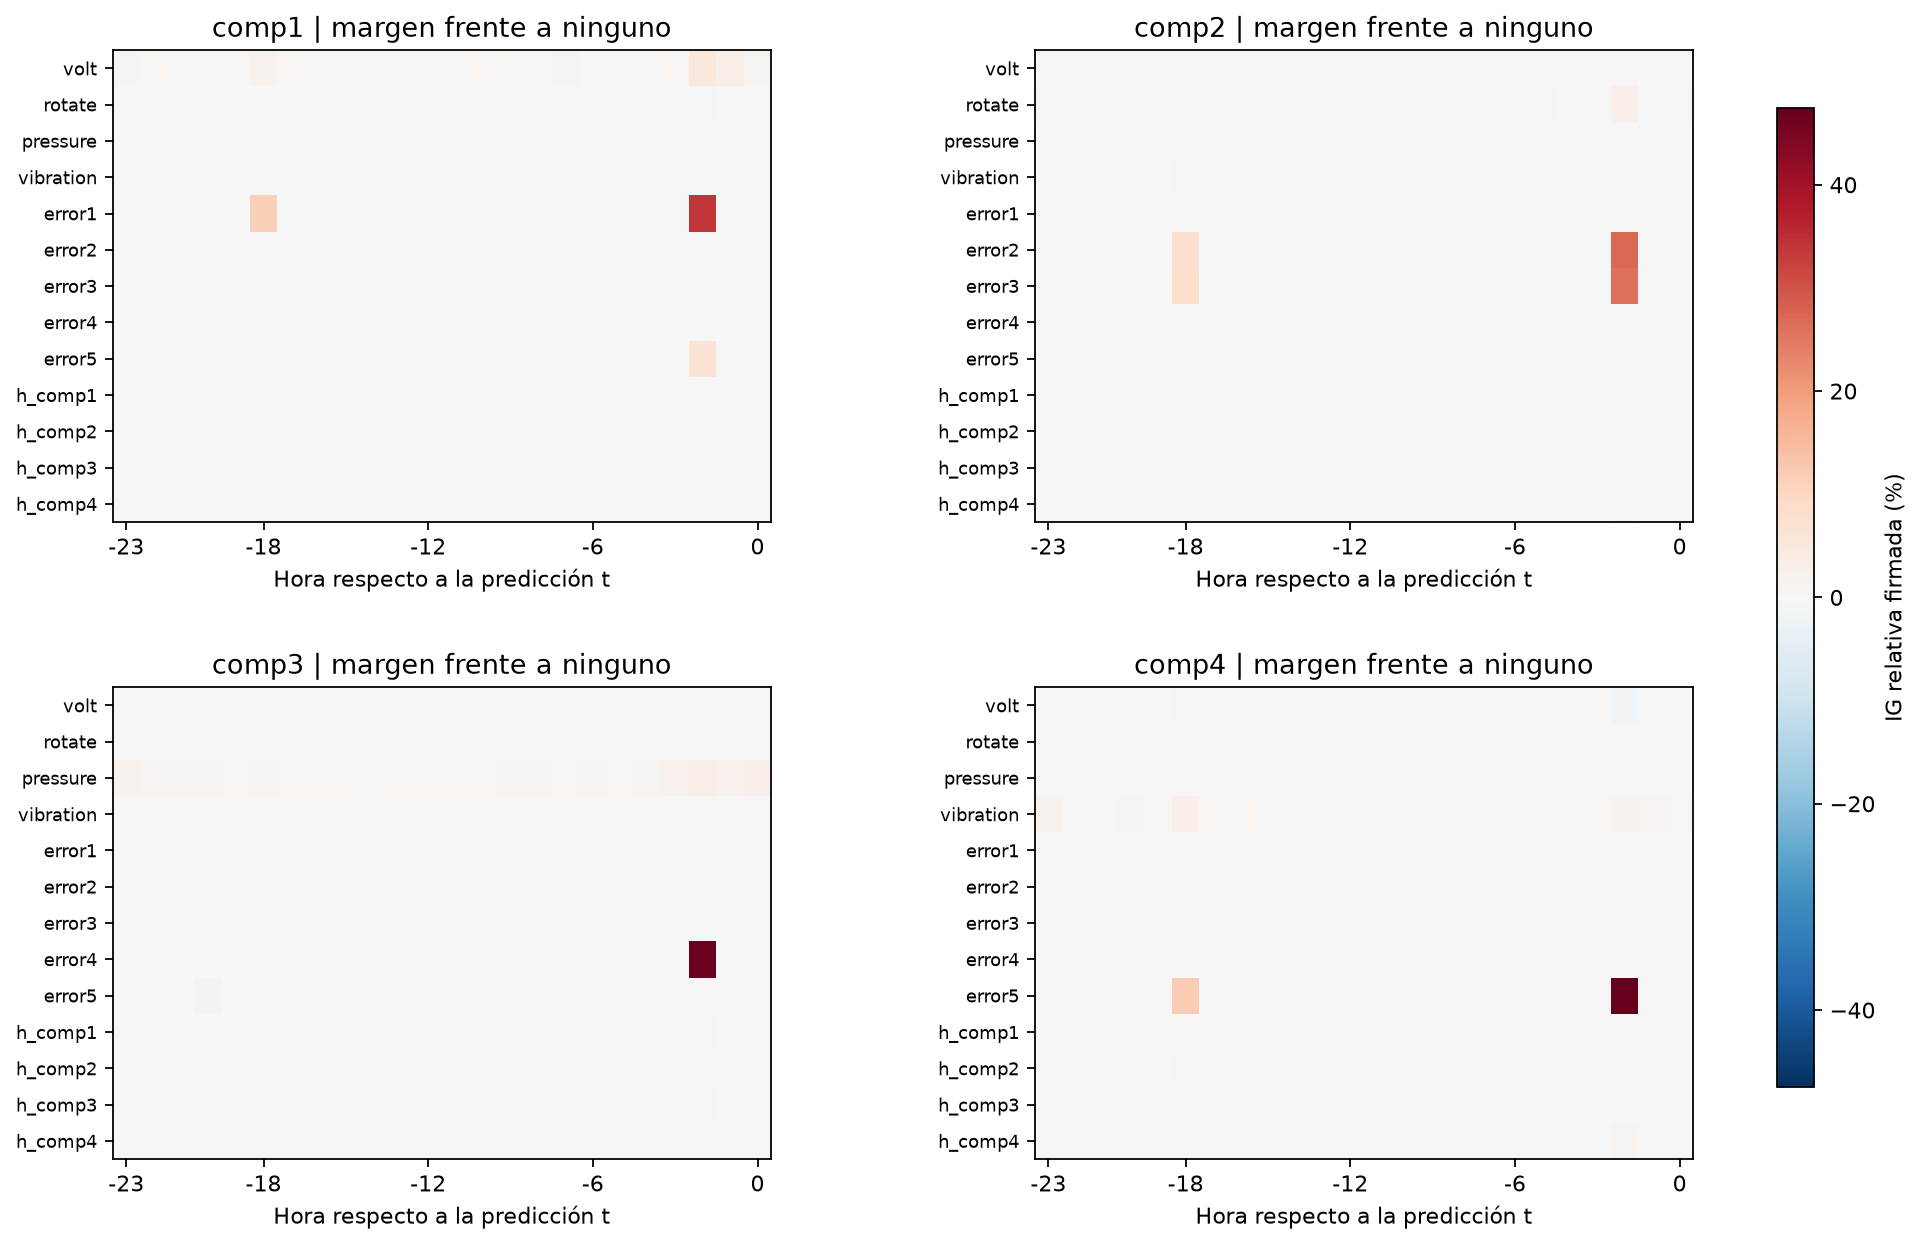

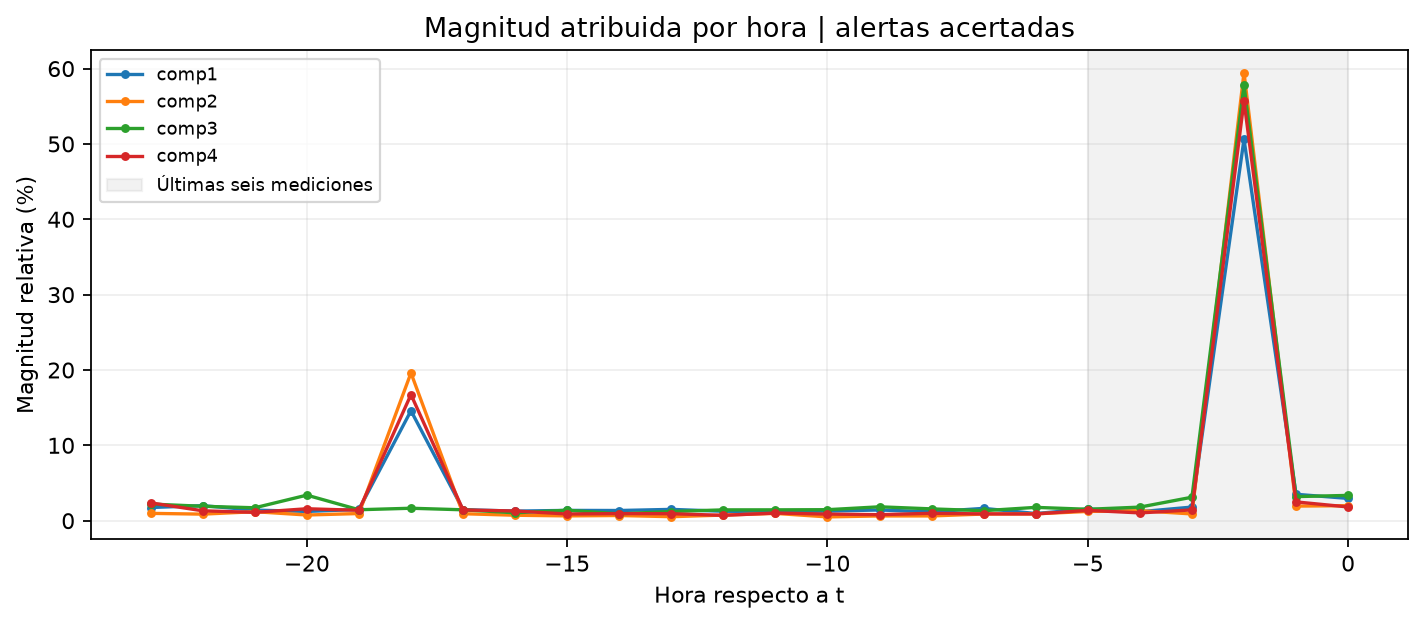

In [5]:
filas_canales_12, filas_horas_12, filas_ventanas_12 = [], [], []
mapas_firmados_12 = {}
mapas_magnitud_12 = {}
for caso in casos_12.itertuples(index=False):
    for tarea in ["Componente", "Binaria"]:
        atrib = explicaciones_12[(int(caso.caso), tarea)]["atribuciones"]
        firmado = atrib.mean(axis=0)
        magnitud = np.abs(atrib).mean(axis=0)
        escala = float(magnitud.sum())
        assert escala > 0
        mapas_firmados_12[(int(caso.caso), tarea)] = firmado / escala * 100
        mapas_magnitud_12[(int(caso.caso), tarea)] = magnitud / escala * 100
        for numero, canal in enumerate(canales_12):
            filas_canales_12.append({"caso": int(caso.caso), "componente": caso.componente,
                "grupo": caso.grupo, "tarea": tarea, "canal": canal,
                "magnitud_pct": float(magnitud[:, numero].sum() / escala * 100),
                "aporte_firmado_pct": float(firmado[:, numero].sum() / escala * 100),
                "apoyo_positivo_pct": float(np.clip(firmado[:, numero], 0, None).sum() / escala * 100)})
        for posicion, hora in enumerate(range(-23, 1)):
            filas_horas_12.append({"caso": int(caso.caso), "componente": caso.componente,
                "grupo": caso.grupo, "tarea": tarea, "hora_relativa": hora,
                "magnitud_pct": float(magnitud[posicion].sum() / escala * 100),
                "aporte_firmado_pct": float(firmado[posicion].sum() / escala * 100)})
atribuciones_canales_12 = pd.DataFrame(filas_canales_12)
atribuciones_horas_12 = pd.DataFrame(filas_horas_12)
resumen_canales_12 = atribuciones_canales_12.groupby(["componente", "grupo", "tarea", "canal"], as_index=False)[
    ["magnitud_pct", "aporte_firmado_pct", "apoyo_positivo_pct"]].mean()
resumen_horas_12 = atribuciones_horas_12.groupby(["componente", "grupo", "tarea", "hora_relativa"], as_index=False)[
    ["magnitud_pct", "aporte_firmado_pct"]].mean()
resumen_principal_12 = []
for componente in clases_12[1:]:
    for grupo in ["Acertada", "No acertada"]:
        for tarea in ["Componente", "Binaria"]:
            canales = resumen_canales_12.loc[(resumen_canales_12.componente == componente) &
                         (resumen_canales_12.grupo == grupo) & (resumen_canales_12.tarea == tarea)]
            horas = resumen_horas_12.loc[(resumen_horas_12.componente == componente) &
                         (resumen_horas_12.grupo == grupo) & (resumen_horas_12.tarea == tarea)]
            if canales.empty:
                continue
            mayor = canales.loc[canales.magnitud_pct.idxmax()]
            apoyo = canales.loc[canales.apoyo_positivo_pct.idxmax()]
            hora = horas.loc[horas.magnitud_pct.idxmax()]
            resumen_principal_12.append({"componente": componente, "grupo": grupo, "tarea": tarea,
                "canal_mayor_magnitud": mayor.canal, "magnitud_pct": mayor.magnitud_pct,
                "canal_mayor_apoyo": apoyo.canal if apoyo.apoyo_positivo_pct > 0 else "sin apoyo positivo",
                "hora_mayor_magnitud": int(hora.hora_relativa),
                "magnitud_ultimas_6h_pct": horas.loc[horas.hora_relativa >= -5, "magnitud_pct"].sum()})
resumen_principal_12 = pd.DataFrame(resumen_principal_12)
display(resumen_principal_12.round(3))

# Dibujar el promedio firmado de casos acertados con la misma escala para los cuatro componentes.
mapas_componentes_12 = {}
for componente in clases_12[1:]:
    ids = casos_12.loc[(casos_12.componente == componente) & (casos_12.grupo == "Acertada"), "caso"]
    mapas_componentes_12[componente] = np.mean([mapas_firmados_12[(int(i), "Componente")] for i in ids], axis=0)
limite_color_12 = max(np.abs(mapa).max() for mapa in mapas_componentes_12.values())
nombres_cortos_12 = ["volt", "rotate", "pressure", "vibration"] + ["error" + str(i) for i in range(1, 6)] + ["h_comp" + str(i) for i in range(1, 5)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
for eje, componente in zip(ejes.flat, clases_12[1:]):
    imagen = eje.imshow(mapas_componentes_12[componente].T, aspect="auto", cmap="RdBu_r",
                        vmin=-limite_color_12, vmax=limite_color_12)
    eje.set(title=componente + " | margen frente a ninguno", xticks=[0, 5, 11, 17, 23],
            xticklabels=[-23, -18, -12, -6, 0], yticks=range(13), yticklabels=nombres_cortos_12,
            xlabel="Hora respecto a la predicción t")
    eje.tick_params(axis="y", labelsize=8)
fig.subplots_adjust(left=.10, right=.86, wspace=.40, hspace=.35)

# Reservar un espacio propio para la escala, sin cubrir los mapas.
barra_color = fig.add_axes([.90, .16, .018, .68])
fig.colorbar(imagen, cax=barra_color, label="IG relativa firmada (%)")
plt.show()

# Separar el resumen temporal por componente, sin mezclar las 24 posiciones.
fig, eje = plt.subplots(figsize=(9, 4))
for componente in clases_12[1:]:
    datos = resumen_horas_12.loc[(resumen_horas_12.componente == componente) &
             (resumen_horas_12.grupo == "Acertada") & (resumen_horas_12.tarea == "Componente")]
    eje.plot(datos.hora_relativa, datos.magnitud_pct, marker="o", markersize=3, label=componente)
eje.set(title="Magnitud atribuida por hora | alertas acertadas", xlabel="Hora respecto a t", ylabel="Magnitud relativa (%)")
eje.axvspan(-5, 0, color="gray", alpha=.10, label="Últimas seis mediciones")
eje.legend(fontsize=8)
eje.grid(alpha=.2)
fig.tight_layout()
plt.show()

### Qué canales y horas impulsan las alertas

En los cuatro ejemplos acertados de cada componente, el canal con mayor magnitud también es el de mayor apoyo positivo al margen frente a “ninguno”:

| Componente | Canal principal | Magnitud relativa | Magnitud en las últimas seis mediciones |
|---|---|---:|---:|
| comp1 | error1 horario | 45.35 % | 61.63 % |
| comp2 | error2 horario | 35.42 % | 66.86 % |
| comp3 | error4 horario | 46.57 % | 70.80 % |
| comp4 | error5 horario | 59.59 % | 63.86 % |

La salida binaria presenta los mismos canales principales en estos casos. Los porcentajes describen la distribución de la magnitud de IG, **no la probabilidad de falla**. En los mapas, rojo apoya el puntaje y azul lo reduce respecto a las referencias sanas. `error1`–`error5` abrevian los indicadores horarios y `h_comp1`–`h_comp4`, las horas desde el reemplazo.

El máximo temporal agregado aparece en **t−2** para los cuatro componentes. Hay que leerlo con cuidado: se seleccionaron estados de alerta sostenida de al menos tres horas, lo que puede favorecer ejemplos cercanos a dos horas después del inicio de la señal. No demuestra que t−2 sea siempre la hora decisiva ni que falten dos horas para una falla. La ventana termina en la hora de predicción t.

Los casos no acertados muestran diferencias. Comp1 conserva error1; el único ejemplo de comp2 destaca error5 y los dos de comp3 destacan pressure. En comp4, vibration tiene la mayor magnitud absoluta, pero error5 aporta el mayor apoyo positivo. Una contribución grande puede reducir una predicción: magnitud y apoyo no son lo mismo. Estas diferencias se describen sin generalizarlas a partir de tan pocos casos.

## 7. Sensibilidad a las referencias y lectura de un caso local

Volvemos a ordenar los canales usando cada referencia por separado. Si cambia el líder, la explicación depende de qué antecedente sano se eligió. Tres referencias no cubren todas las posibles y no constituyen un intervalo estadístico.

Para mostrar el signo en una ventana concreta, elegimos el primer error de comp1 si existe; si no, el primer error disponible y, por último, el primer caso acertado. La regla se fija antes de observar sus mapas. Mostramos tanto la señal binaria como el contraste del componente, junto con sus sensores y los antecedentes sanos.

,componente,referencia,canal_dominante,magnitud_pct
0,comp1,1,error1_horario,43.914
1,comp1,2,error1_horario,44.128
2,comp1,3,error1_horario,47.978
3,comp2,1,error2_horario,33.802
4,comp2,2,error2_horario,36.521
5,comp2,3,error2_horario,36.107
6,comp3,1,error4_horario,43.926
7,comp3,2,error4_horario,47.011
8,comp3,3,error4_horario,49.422
9,comp4,1,error5_horario,57.646


,caso,componente,grupo,machineID,datetime,clase_real,probabilidad_binaria,probabilidad_componente
4,4,comp1,No acertada,80,2015-10-01,ninguno,0.80642,0.97278


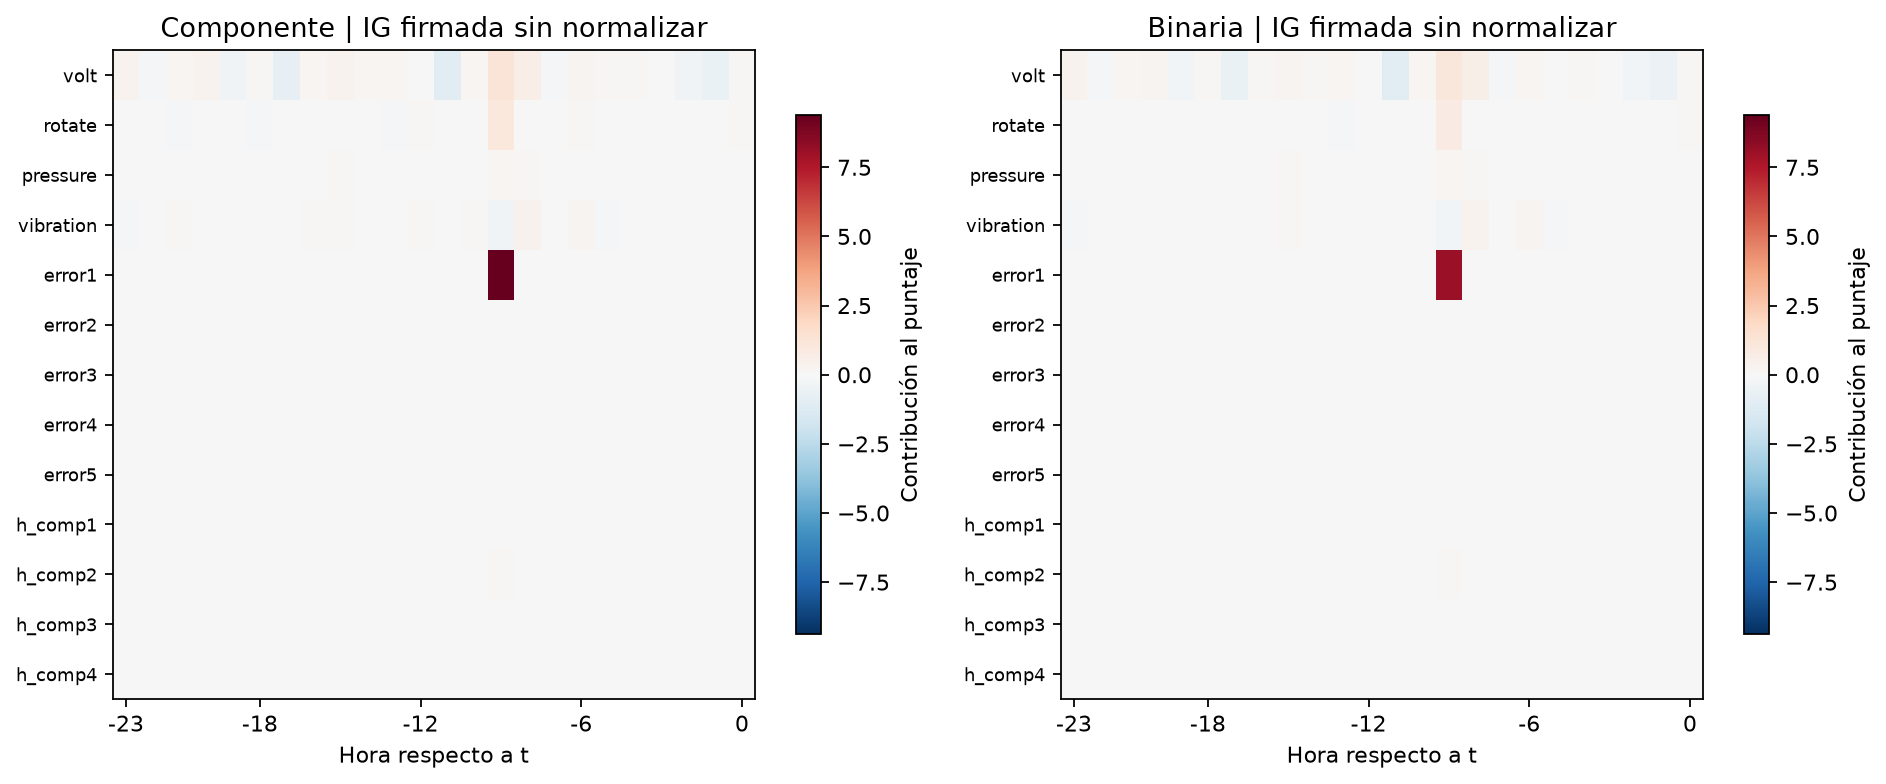

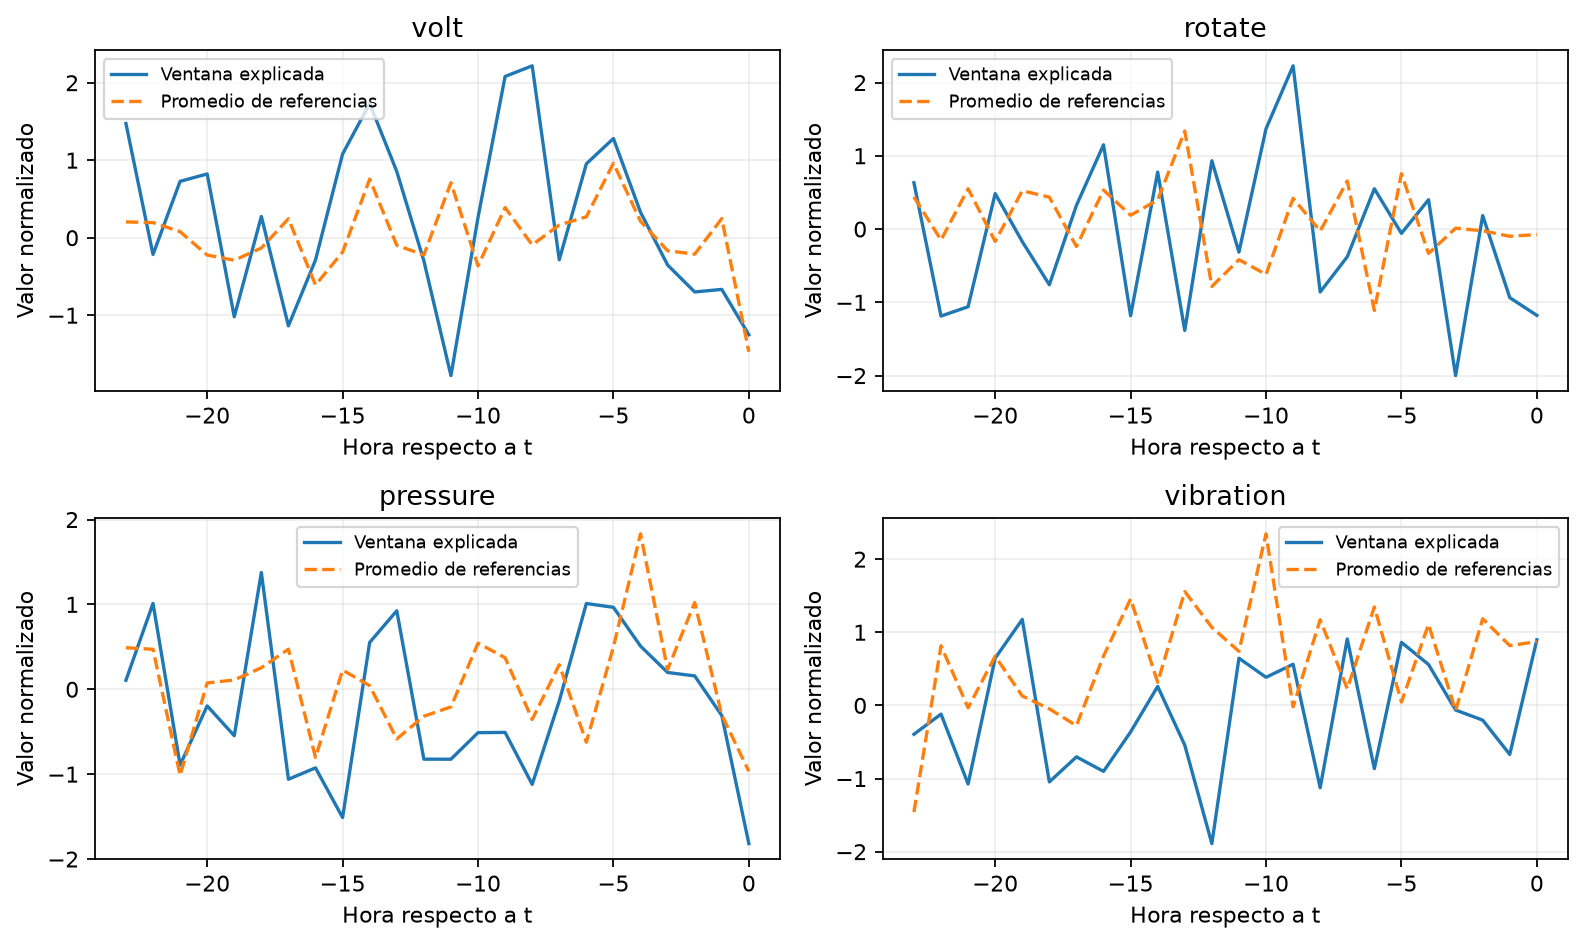

In [6]:
sensibilidad_referencias_12 = []
for componente in clases_12[1:]:
    ids = casos_12.loc[(casos_12.componente == componente) & (casos_12.grupo == "Acertada"), "caso"]
    for referencia in range(3):
        aportes = []
        for identificador in ids:
            a = np.abs(explicaciones_12[(int(identificador), "Componente")]["atribuciones"][referencia])
            aportes.append(a.sum(axis=0) / a.sum() * 100)
        promedio = np.mean(aportes, axis=0)
        orden = np.argsort(promedio)[::-1]
        sensibilidad_referencias_12.append({"componente": componente, "referencia": referencia + 1,
            "canal_dominante": canales_12[orden[0]], "magnitud_pct": promedio[orden[0]]})
sensibilidad_referencias_12 = pd.DataFrame(sensibilidad_referencias_12)
display(sensibilidad_referencias_12.round(3))

# Aplicar la regla local sin elegir según el tamaño de sus atribuciones.
locales = casos_12.loc[(casos_12.componente == "comp1") & (casos_12.grupo == "No acertada")]
if locales.empty:
    locales = casos_12.loc[casos_12.grupo == "No acertada"]
if locales.empty:
    locales = casos_12
caso_local_12 = locales.iloc[0]
id_local_12 = int(caso_local_12.caso)
display(casos_12.loc[casos_12.caso == id_local_12].drop(columns=["indice_validacion", "codigo_componente"]))
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
limite_local = max(np.abs(explicaciones_12[(id_local_12, tarea)]["atribuciones"].mean(axis=0)).max()
                   for tarea in ["Componente", "Binaria"])
for eje, tarea in zip(ejes, ["Componente", "Binaria"]):
    mapa = explicaciones_12[(id_local_12, tarea)]["atribuciones"].mean(axis=0)
    imagen = eje.imshow(mapa.T, aspect="auto", cmap="RdBu_r", vmin=-limite_local, vmax=limite_local)
    eje.set(title=tarea + " | IG firmada sin normalizar", yticks=range(13), yticklabels=nombres_cortos_12,
            xticks=[0, 5, 11, 17, 23], xticklabels=[-23, -18, -12, -6, 0], xlabel="Hora respecto a t")
    eje.tick_params(axis="y", labelsize=8)
    fig.colorbar(imagen, ax=eje, shrink=.8, label="Contribución al puntaje")
fig.tight_layout()
plt.show()
local = explicaciones_12[(id_local_12, "Componente")]
fig, ejes = plt.subplots(2, 2, figsize=(10, 6))
for numero, eje in enumerate(ejes.flat):
    eje.plot(range(-23, 1), local["ventana"][:, numero], label="Ventana explicada")
    eje.plot(range(-23, 1), local["referencias"][:, :, numero].mean(axis=0), "--", label="Promedio de referencias")
    eje.set(title=canales_12[numero], xlabel="Hora respecto a t", ylabel="Valor normalizado")
    eje.legend(fontsize=8)
    eje.grid(alpha=.2)
fig.tight_layout()
plt.show()

### Sensibilidad y ejemplo no acertado

Al cambiar entre las tres referencias sanas, el canal principal de los casos acertados se conserva: error1 para comp1, error2 para comp2, error4 para comp3 y error5 para comp4. Sus porcentajes cambian, por lo que la elección de referencia sí influye en cuánto aporte se asigna. La estabilidad observada se limita a estas referencias y casos.

El ejemplo local, elegido antes de examinar los mapas, corresponde a la máquina 80 el 1 de octubre a las 00:00. Predijo comp1 con probabilidad multiclase aproximada de 0.973 y probabilidad binaria de 0.806, aunque la etiqueta era “ninguno”. Esto significa que no había una falla etiquetada en las siguientes 24 horas; no afirma que la máquina nunca falle.

En el margen de comp1, error1 aporta aproximadamente **+9.38 unidades**, sumando las horas y promediando las referencias. Es el aporte positivo más grande del ejemplo. Las señales y los mapas muestran cómo el modelo puede apoyar una predicción no acertada; no prueban que ese error cause una falla ni que todas sus apariciones sean falsas alarmas. Las curvas de sensores muestran valores normalizados, no sus unidades físicas originales.

## 8. Contrastar con el EDA de entrenamiento

El EDA 02 encontró en las últimas 24 horas previas a falla: mayor voltaje para comp1, menor rotación para comp2, mayor presión para comp3 y mayor vibración para comp4. Recuperamos su tabla guardada, sin ejecutar otra exploración ni consultar prueba.

Contrastamos tres cosas: qué sensor destacó en el EDA, si aparece entre los canales importantes del modelo y si la ventana explicada presenta un desplazamiento del sensor en la misma dirección frente a las referencias.

Las comparaciones tienen límites distintos: el EDA se hizo con enero–agosto, ventanas alineadas a la falla y controles emparejados; IG usa casos de octubre, horas respecto a la predicción y tres referencias de entrenamiento. El EDA dividió por la desviación por máquina; la red usa normalización global. Por eso comparamos **sensor y dirección**, no exigimos igualdad de magnitudes ni alineamos las horas como si tuvieran el mismo origen.

Un sensor puede tener atribución grande porque se opone a una predicción, no porque la apoye. La tabla conserva tanto el aporte firmado como el desplazamiento observado. Coincidir con el EDA no prueba causalidad; discrepar requiere analizar el contexto, no corregir a mano los mapas.

In [7]:
def leer_tabla_eda_12():
    """Recuperar la tabla de cuatro sensores por componente ya guardada en el EDA."""
    fuente = nbformat.read(ruta_repo / "EDA" / "02_análisis_exploratorio.ipynb", as_version=4)
    sensores = canales_12[:4]
    for celda in fuente.cells:
        for salida in celda.get("outputs", []):
            html = salida.get("data", {}).get("text/html")
            if not html:
                continue
            for tabla in BeautifulSoup(html, "html.parser").find_all("table"):
                columnas = [valor.get_text(strip=True) for valor in tabla.thead.find_all("tr")[0].find_all("th")]
                columnas = [valor for valor in columnas if valor]
                filas, etiquetas = [], []
                for fila in tabla.tbody.find_all("tr"):
                    etiquetas.append(fila.find("th").get_text(strip=True))
                    filas.append([valor.get_text(strip=True) for valor in fila.find_all("td")])
                if columnas == sensores and etiquetas == clases_12[1:]:
                    return pd.DataFrame(filas, index=etiquetas, columns=columnas).astype(float)
    raise ValueError("No se encontró la tabla por componente del EDA guardado.")


tabla_eda_12 = leer_tabla_eda_12()
display(tabla_eda_12)
contraste_eda_12 = []
for componente in clases_12[1:]:
    sensor_eda = tabla_eda_12.loc[componente].abs().idxmax()
    direccion_eda = np.sign(tabla_eda_12.loc[componente, sensor_eda])
    canal_numero = canales_12.index(sensor_eda)
    ranking = resumen_canales_12.loc[(resumen_canales_12.componente == componente) &
                 (resumen_canales_12.grupo == "Acertada") & (resumen_canales_12.tarea == "Componente")].sort_values("magnitud_pct", ascending=False)
    ranking_sensores = ranking.loc[ranking.canal.isin(canales_12[:4])]
    posicion_eda = ranking.canal.tolist().index(sensor_eda) + 1
    fila_sensor = ranking.loc[ranking.canal == sensor_eda].iloc[0]
    desplazamientos = []
    ids = casos_12.loc[(casos_12.componente == componente) & (casos_12.grupo == "Acertada"), "caso"]
    for identificador in ids:
        datos = explicaciones_12[(int(identificador), "Componente")]
        desplazamientos.append(float(datos["ventana"][:, canal_numero].mean() - datos["referencias"][:, :, canal_numero].mean()))
    desplazamiento = float(np.mean(desplazamientos))
    contraste_eda_12.append({"componente": componente, "sensor_EDA": sensor_eda,
        "diferencia_EDA_DE_maquina": tabla_eda_12.loc[componente, sensor_eda],
        "sensor_IG_dominante": ranking_sensores.iloc[0].canal,
        "posición_sensor_EDA_entre_13": posicion_eda, "magnitud_sensor_EDA_pct": fila_sensor.magnitud_pct,
        "aporte_firmado_sensor_EDA_pct": fila_sensor.aporte_firmado_pct,
        "desplazamiento_normalizado_vs_refs": desplazamiento,
        "misma_direccion_observada": bool(np.sign(desplazamiento) == direccion_eda)})
contraste_eda_12 = pd.DataFrame(contraste_eda_12)
display(contraste_eda_12.round(4))

,volt,rotate,pressure,vibration
comp1,1.268,-0.029,0.046,-0.017
comp2,0.047,-1.445,0.046,0.056
comp3,0.066,0.000,2.196,-0.029
comp4,-0.033,-0.087,0.068,1.779


,componente,sensor_EDA,diferencia_EDA_DE_maquina,sensor_IG_dominante,posición_sensor_EDA_entre_13,magnitud_sensor_EDA_pct,aporte_firmado_sensor_EDA_pct,desplazamiento_normalizado_vs_refs,misma_direccion_observada
0,comp1,volt,1.268,volt,2,33.7154,24.0804,1.0700,True
1,comp2,rotate,-1.445,rotate,3,12.1023,10.7321,-1.5689,True
2,comp3,pressure,2.196,pressure,2,34.4311,31.9683,2.3058,True
3,comp4,vibration,1.779,vibration,2,26.0045,20.0121,1.5381,True


### Comparación con el análisis exploratorio

Al restringir la comparación a los cuatro sensores, el sensor más importante por componente coincide con el EDA: **volt para comp1, rotate para comp2, pressure para comp3 y vibration para comp4**. Frente a las referencias sanas, los casos acertados muestran respectivamente volt mayor, rotate menor, pressure mayor y vibration mayor. Las cuatro direcciones coinciden con el patrón exploratorio.

Estos sensores representan aproximadamente 33.72 %, 12.10 %, 34.43 % y 26.00 % de la magnitud del margen de su componente. Sin embargo, **al incluir los 13 canales, dominan los indicadores de error**, como mostró la tabla anterior. La coincidencia entre sensores no significa que el modelo dependa exclusivamente de ellos.

Un aporte positivo no significa que el sensor deba aumentar: una caída de rotate puede apoyar la predicción de comp2. Además, el EDA resumía horas anteriores a la falla y usaba escalas por máquina; aquí se explican las 24 mediciones anteriores a una predicción con normalización global de entrenamiento. Se comparan sensores y direcciones, no valores numéricos como si ambas gráficas midieran lo mismo. El EDA pertenece a entrenamiento y los ejemplos explicados a octubre de validación; no se utilizó prueba.

## 9. Qué respondimos y qué queda pendiente

Para estos ejemplos del Transformer, las alertas se apoyan especialmente en errores horarios y en las mediciones recientes. Los sensores destacados por componente conservan las direcciones observadas en el EDA. Los ejemplos no acertados muestran que esas señales también pueden apoyar una predicción equivocada.

IG explica diferencias respecto a ventanas sanas; no identifica causas físicas ni garantiza que retirar una señal evite una falla. Octubre ya participó en el desarrollo del modelo, de modo que este análisis es descriptivo y no una evaluación independiente. No se eligió otro modelo ni se ajustó su umbral con estas atribuciones.

Las explicaciones y sus tablas quedan dentro de este notebook; no se exportan figuras, CSV ni pesos. IG no entrena el modelo y los parámetros se comprobaron al terminar. La selección usa etiquetas de validación solo para describir casos, sin modificar entrenamiento, normalizadores ni configuración.

Esto cubre canales y horas de la ventana, signos, sensibilidad a referencias y contraste con el EDA. La política económica corresponde al paso 3.4. Prueba permanece reservada para la evaluación final una sola vez, con todas las decisiones fijadas.